In [1]:
import numpy as np
from pathlib import Path
from safetensors.numpy import load_file, save_file
from tqdm import tqdm
import argparse
import json
from matplotlib import pyplot as plt
from functools import partial

In [2]:
def make_path(data_path):
    try:
        assert Path.is_dir(data_path) == True
    except AssertionError:
        data_path = Path("..", data_path)
        assert Path.is_dir(data_path) == True, f"{data_path} is not a valid path."
    return data_path

In [3]:
# Model colors - consistent across all plots
MODEL_COLORS = {
    'dino': '#0A5EB0',        # Blue
    'clip_image': '#DC143C',   # Crimson
    'clip_text': '#FF8C00',    # Dark Orange
    'deepseek': '#2E8B57',     # Sea Green
    'igpt': '#399918',          # Green (for future),
    'llama': '#F54927'
}

# Model display names
MODEL_NAMES = {
    'dino': 'DinoV2',
    'clip_image': 'CLIP-Image',
    'clip_text': 'CLIP-Text',
    'deepseek': 'DeepSeek-V3',
    'igpt': 'ImageGPT',
    'llama': 'LLama3.1-8B'
}

TARGET_LAYERS = {
    'deepseek' : 52,
    'llama' : 20,
    'dino' : 24,
    'clip_text' : 12,
    'igpt' : 20
}

N_LAYERS = {
    'deepseek' : 60,
    'llama' : 32,
    'dino' : 24,
    'igpt' : 48
}

In [4]:
def load_inf_imb_data(data_path, n_layers):
    """Load information imbalance data from safetensors files."""
    inf_imb = {}
    for i in range(1, n_layers + 1):
        inf_imb[f"layer_{i}"] = load_file(Path(data_path, f"layer_{i}.safetensors"))
    return inf_imb

In [5]:
def extract_matrices(inf_imb, n_layers):
    """Extract information and multiplicity matrices from loaded data."""
    n_rows = inf_imb.get("layer_1").get('ranks').shape[0]
    
    inf_matrix = np.empty((n_layers, n_rows, 2))
    mult_matrix = np.empty((n_layers, n_rows, 2))
    
    for i in range(n_layers):
        inf_matrix[i, :, 0] = inf_imb[f"layer_{i+1}"]["ranks"]
        inf_matrix[i, :, 1] = inf_imb[f"layer_{i+1}"]["r_ranks"]
        mult_matrix[i, :, 0] = inf_imb[f"layer_{i+1}"]["cards"]
        mult_matrix[i, :, 1] = inf_imb[f"layer_{i+1}"]["r_cards"]
    
    return inf_matrix, mult_matrix, n_rows


def compute_mean_inf_imb(inf_matrix, mult_matrix, n_layers, n_rows, sample_size):
    """Compute mean information imbalance for each layer."""
    n_cols = sample_size - n_rows
    
    # Forward direction
    forward_means = np.zeros(n_layers)
    for i in range(n_layers):
        vals = inf_matrix[i, :, 0]
        cards = mult_matrix[i, :, 0]
        forward_means[i] = 2. * (np.sum(vals) / np.sum(cards)) / (n_cols - 2.)
    
    # Backward direction
    backward_means = np.zeros(n_layers)
    for i in range(n_layers):
        vals = inf_matrix[i, :, 1]
        cards = mult_matrix[i, :, 1]
        backward_means[i] = 2. * (np.sum(vals) / np.sum(cards)) / (n_cols - 2.)
    
    return forward_means, backward_means


def bootstrap(rng, inf_matrix, mult_matrix, n_replicas, bootstrap_size, n_layers, n_rows, sample_size):
    """Perform bootstrap analysis on information imbalance data."""
    n_cols = sample_size - n_rows
    
    inf_forward = np.empty((n_layers, n_replicas))
    inf_backward = np.empty((n_layers, n_replicas))
    
    for layer_id in tqdm(np.arange(n_layers), desc="Bootstrap layers"):
        ranks_forward = inf_matrix[layer_id, :, 0]
        ranks_backward = inf_matrix[layer_id, :, 1]
        cards_forward = mult_matrix[layer_id, :, 0]
        cards_backward = mult_matrix[layer_id, :, 1]
        
        for i in range(n_replicas):
            indices = rng.choice(n_rows, size=bootstrap_size, replace=True)
            inf_forward[layer_id, i] = 2. * (np.sum(ranks_forward[indices]) / np.sum(cards_forward[indices])) / (n_cols - 2.)
            inf_backward[layer_id, i] = 2. * (np.sum(ranks_backward[indices]) / np.sum(cards_backward[indices])) / (n_cols - 2.)
    
    return inf_forward, inf_backward

In [6]:
def save_bootstrap_results(output_path, forward_data, backward_data, config):
    """Save bootstrap results and configuration."""
    # Save numpy arrays
    np.save(Path(output_path, f"{config['model_a']}_{config['model_b']}_{config['layer']}.npy"), forward_data)
    np.save(Path(output_path, f"{config['model_b']}_{config['model_a']}_{config['layer']}.npy"), backward_data)
    
    # Save configuration
    with open(Path(output_path, "bootstrap_config.json"), 'w') as f:
        json.dump(config, f, indent=2)
    
    # Save summary statistics
    summary = {
        'forward_mean': np.mean(forward_data, axis=1).tolist(),
        'forward_std': np.std(forward_data, axis=1).tolist(),
        'backward_mean': np.mean(backward_data, axis=1).tolist(),
        'backward_std': np.std(backward_data, axis=1).tolist(),
        'n_layers': forward_data.shape[0],
        'n_replicas': forward_data.shape[1]
    }
    
    with open(Path(output_path, f"summary_{config['model_a']}_{config['model_b']}.json"), 'w') as f:
        json.dump(summary, f, indent=2)

In [7]:
def make_comparison(to_model, from_model, rng, n_replicas = 100, bootstrap_size = 750, sample_size = 5_000, base_dir=None, hamming=True):
    if base_dir is None:
        base_dir = Path("data")
    AtoB = make_path(Path(base_dir, f"{to_model}_{from_model}", "l2")) if hamming is False else make_path(Path(base_dir, f"{to_model}_{from_model}", "hamming"))
    print(f"Loading {AtoB}")
    inf_imb = load_inf_imb_data(AtoB, N_LAYERS[from_model])
    inf_matrix, mult_matrix, n_rows = extract_matrices(inf_imb, N_LAYERS[from_model])
    inf_forward, inf_backward = bootstrap(rng, inf_matrix, mult_matrix, n_replicas, bootstrap_size, N_LAYERS[from_model], n_rows, sample_size)
    forward_mean = np.mean(inf_forward, axis=1)
    forward_std = np.std(inf_forward, axis=1)
    backward_mean = np.mean(inf_backward, axis=1)
    backward_std = np.std(inf_backward, axis=1)
    return [forward_mean, forward_std], [backward_mean, backward_std]

In [8]:
rng = np.random.default_rng(2019)
n_replicas = 500
bootstrap_size = 1500
sample_size = 5_000
base_dir = make_path(Path("data"))
assert Path(base_dir).is_dir() == True, f"{base_dir} doesn't exist!"

In [9]:
DO_HAMMING = True

In [10]:
compare_deepseek = partial(make_comparison, to_model="deepseek", rng=rng, base_dir=base_dir, hamming=DO_HAMMING)

In [11]:
igpt_fwd, igpt_bwd = compare_deepseek(from_model="igpt")

Loading ../data/deepseek_igpt/hamming


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 200.34it/s]


In [12]:
dino_fwd, dino_bwd = compare_deepseek(from_model="dino")

Loading ../data/deepseek_dino/hamming


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 205.31it/s]


In [13]:
llama_fwd, llama_bwd = compare_deepseek(from_model="llama")

Loading ../data/deepseek_llama/hamming


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 32/32 [00:00<00:00, 188.93it/s]


In [14]:
dino_igpt_fwd, dino_igpt_bwd = make_comparison(to_model="dino", from_model="igpt", rng=rng, hamming=DO_HAMMING)

Loading ../data/dino_igpt/hamming


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 48/48 [00:00<00:00, 195.06it/s]


In [15]:
igpt_dino_fwd, igpt_dino_bwd = make_comparison(to_model="igpt", from_model="dino", rng=rng, hamming=DO_HAMMING)

Loading ../data/igpt_dino/hamming


Bootstrap layers: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [00:00<00:00, 191.71it/s]


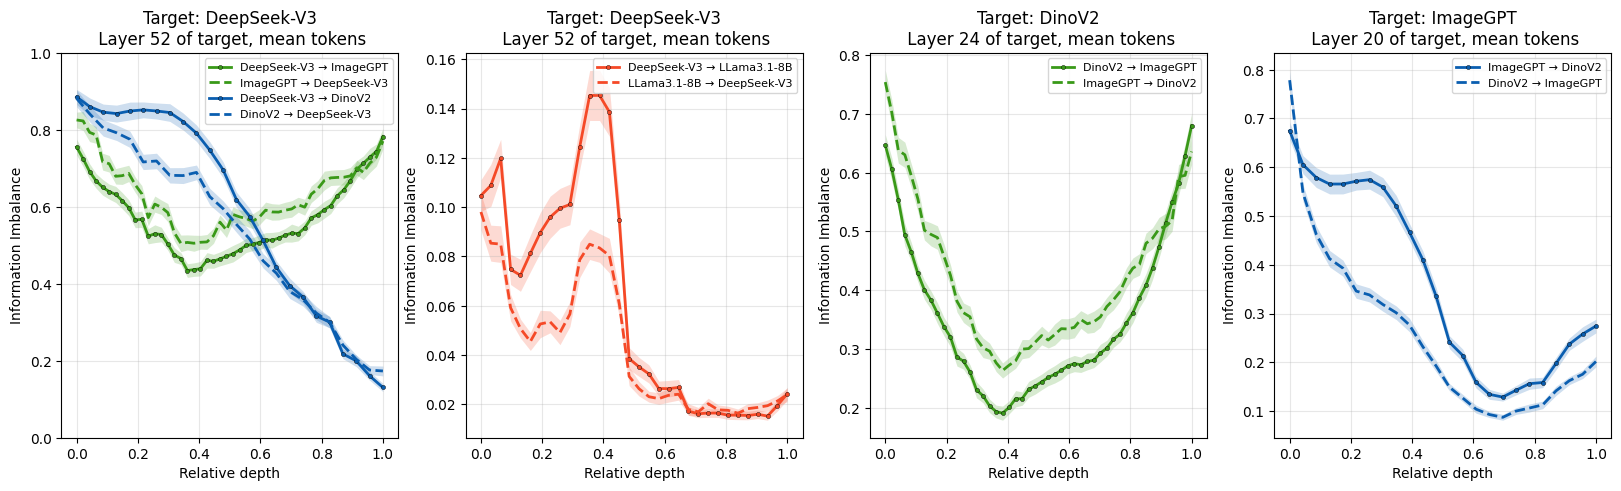

In [16]:
# Plot forward direction (A → B)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
ylim = (0, 1)
x = {}
x['igpt'] = np.linspace(0, 1, N_LAYERS['igpt'])
x['deepseek'] = np.linspace(0, 1, N_LAYERS['deepseek'])
x['llama'] = np.linspace(0, 1, N_LAYERS['llama'])
x['dino'] = np.linspace(0, 1, N_LAYERS['dino'])

label_forward = f"{MODEL_NAMES['deepseek']} → {MODEL_NAMES['igpt']}"
ax = axes[0]
ax.plot(x['igpt'], igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], igpt_fwd[0] - igpt_fwd[1], igpt_fwd[0] + igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['igpt'], igpt_bwd[0], '--', color=MODEL_COLORS['igpt'], label=label_backward, linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], igpt_bwd[0] - igpt_bwd[1], igpt_bwd[0] + igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])

label_forward = f"{MODEL_NAMES['deepseek']} → {MODEL_NAMES['dino']}"
ax.plot(x['dino'], dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], dino_fwd[0] - dino_fwd[1], dino_fwd[0] + dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
label_backward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['dino'], dino_bwd[0], '--', color=MODEL_COLORS['dino'], label=label_backward, linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], dino_bwd[0] - dino_bwd[1], dino_bwd[0] + dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
title = f"Target: {MODEL_NAMES['deepseek']}"
ax.set_title(f"{title}\n Layer {TARGET_LAYERS['deepseek']} of target, mean tokens", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=10)
ax.set_ylabel("Information Imbalance", fontsize=10)
ax.set_ylim(ylim)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

ax = axes[1]
label_forward = f"{MODEL_NAMES['deepseek']} → {MODEL_NAMES['llama']}"
ax.plot(x['llama'], llama_fwd[0], '-', color=MODEL_COLORS['llama'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['llama'], llama_fwd[0] - llama_fwd[1], llama_fwd[0] + llama_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])
label_backward = f"{MODEL_NAMES['llama']} → {MODEL_NAMES['deepseek']}"
ax.plot(x['llama'], llama_bwd[0], '--', color=MODEL_COLORS['llama'], label=label_backward, linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['llama'], llama_bwd[0] - llama_bwd[1], llama_bwd[0] + llama_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['llama'])
title = f"Target: {MODEL_NAMES['deepseek']}"
ax.set_title(f"{title}\n Layer {TARGET_LAYERS['deepseek']} of target, mean tokens", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=10)
ax.set_ylabel("Information Imbalance", fontsize=10)
#ax.set_ylim(ylim)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

ax = axes[2]
label_forward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['igpt']}"
ax.plot(x['igpt'], dino_igpt_fwd[0], '-', color=MODEL_COLORS['igpt'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['igpt'], dino_igpt_fwd[0] - dino_igpt_fwd[1], dino_igpt_fwd[0] + dino_igpt_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
label_backward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['dino']}"
ax.plot(x['igpt'], dino_igpt_bwd[0], '--', color=MODEL_COLORS['igpt'], label=label_backward, linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['igpt'], dino_igpt_bwd[0] - dino_igpt_bwd[1], dino_igpt_bwd[0] + dino_igpt_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['igpt'])
title = f"Target: {MODEL_NAMES['dino']}"
ax.set_title(f"{title}\n Layer {TARGET_LAYERS['dino']} of target, mean tokens", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=10)
ax.set_ylabel("Information Imbalance", fontsize=10)
#ax.set_ylim(ylim)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

ax = axes[3]
label_forward = f"{MODEL_NAMES['igpt']} → {MODEL_NAMES['dino']}"
ax.plot(x['dino'], igpt_dino_fwd[0], '-', color=MODEL_COLORS['dino'], 
        label=label_forward, linewidth=2, marker='o', 
        markersize=3, markeredgecolor='black', markeredgewidth=0.3)    
ax.fill_between(x['dino'], igpt_dino_fwd[0] - igpt_dino_fwd[1], igpt_dino_fwd[0] + igpt_dino_fwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
label_backward = f"{MODEL_NAMES['dino']} → {MODEL_NAMES['igpt']}"
ax.plot(x['dino'], igpt_dino_bwd[0], '--', color=MODEL_COLORS['dino'], label=label_backward, linewidth=2, markersize=3, markeredgecolor='black', markeredgewidth=0.3)
ax.fill_between(x['dino'], igpt_dino_bwd[0] - igpt_dino_bwd[1], igpt_dino_bwd[0] + igpt_dino_bwd[1], alpha=0.2, linewidth=0, color=MODEL_COLORS['dino'])
title = f"Target: {MODEL_NAMES['igpt']}"
ax.set_title(f"{title}\n Layer {TARGET_LAYERS['igpt']} of target, mean tokens", fontsize=12)
ax.set_xlabel("Relative depth", fontsize=10)
ax.set_ylabel("Information Imbalance", fontsize=10)
#ax.set_ylim(ylim)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)
plt.savefig(Path("/home/masca/GitHub/deepseek-hidden-states/plots/ii_l2.png") if DO_HAMMING is False else Path("/home/masca/GitHub/deepseek-hidden-states/plots/ii_hamming.png"), dpi = 300)